# Audio training data quality audit

Local CPU analysis, 2026-09-15. Unit: one manifest audio file; derived files retain source groups.
No labels or training files are changed. No new model scores are computed on `sealed`; only data integrity and distributions are inspected there.

## Context and methods
Inspect all train/dev/sealed WAV files, exact decoded PCM hashes, source-group isolation, label missingness, acoustic confounders, and saved V6 dev predictions. Correlation and metadata-only probes reveal possible shortcuts, not proof of mislabeled audio or causal model failure. Spectral features use 16 evenly spaced 4096-sample windows per file; all other audio statistics use the complete waveform. Suspicious files require review rather than automatic deletion.


## Findings

- All 1,936 waveforms decode, satisfy mono 16 kHz finite-audio requirements, and match recorded PCM hashes. No cross-split exact PCM or recorded lineage overlap was found.
- Real music training data: 100 NSynth + 70 FMA; fake music: 946 Echoes. V6 actually used 84 NSynth + 52 FMA versus 687 fake files. Source and label are confounded.
- Seven cheap acoustic features yield V6-expert group OOF AUC 0.8783 but only 0.545 on 50 standalone dev music files. This is a shortcut warning, not proof of the causal failure in MERT.
- Dev and sealed splice panels each contain 40 files but only 20 distinct waveforms. Deduplicating dev changes file EER from 0.3857 to 0.3359 without retraining.
- Twelve training files have more than 80% quiet 100-ms frames: 10 NSynth and 2 Echoes. Review candidates, not automatically bad labels.
- Saved V6 dev music EER: seen-generator + real 0.3167; unseen-generator + real 0.5000; mixtures 0.5250; splices 0.5000. Small, shared-source panels limit generalization claims.


In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import csv, hashlib, json, math, sys
import numpy as np
import scipy
from scipy.stats import pointbiserialr, spearmanr
import soundfile as sf
import sklearn
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'v4_validation').exists():
    ROOT = ROOT.parents[1]
sys.path.insert(0, str(ROOT))
from graph_scoring import official_metrics
OUT = ROOT / 'results/data_audit_20260915'
DATA = ROOT / 'v4_validation'
LABELS = ['FILE_FAKE','VOICE_FAKE','MUSIC_FAKE','VOICE_PRESENT','MUSIC_PRESENT']

def read_csv(path):
    with path.open(encoding='utf-8-sig', newline='') as f:
        return list(csv.DictReader(f))

def save_csv(name, records):
    if not records:
        return
    with (OUT / name).open('w', encoding='utf-8-sig', newline='') as f:
        w=csv.DictWriter(f, fieldnames=list(records[0])); w.writeheader(); w.writerows(records)

rows = [r for split in ['train','dev','sealed'] for r in read_csv(DATA / f'{split}.csv')]
provenance = {r['ID']:r for r in json.loads((DATA/'provenance.json').read_text())['sources']}
v6split = json.loads((ROOT/'results/v6_l40s_20260915/v6_run/split.json').read_text())
expert_ids = {r['ID'] for r in v6split['expert']}
predictions = json.loads((ROOT/'results/v6_l40s_20260915/v6_run/dev_predictions.json').read_text())
pred_by_id = {r['ID']:r for r in predictions}
assert len({r['ID'] for r in rows}) == len(rows), 'Duplicate manifest IDs'
assert {r['ID'] for r in rows} <= provenance.keys(), 'Missing lineage'
assert set(pred_by_id) == {r['ID'] for r in rows if r['split']=='dev'}, 'Prediction join mismatch'
assert all(r[k] in ('','0','1') for r in rows for k in LABELS), 'Malformed labels'
summary = {'row_counts':dict(Counter(r['split'] for r in rows)),
           'versions':{m.__name__:m.__version__ for m in [np,scipy,sf,sklearn]},
           'manifest_sha256':{s:hashlib.sha256((DATA/f'{s}.csv').read_bytes()).hexdigest() for s in ['train','dev','sealed']}}
print(summary['row_counts'])


{'train': 1516, 'dev': 210, 'sealed': 210}


## Full waveform integrity and acoustic measurements

In [2]:
measured=[]; problems=[]
for i,r in enumerate(rows):
    p=DATA/r['path']; meta=provenance[r['ID']]
    try:
        audio,sr=sf.read(p, dtype='float32', always_2d=True)
    except (OSError, sf.LibsndfileError) as e:
        problems.append({'ID':r['ID'],'issue':'decode_error','detail':str(e)}); continue
    if audio.shape[1] != 1 or sr != 16000 or not len(audio) or not np.isfinite(audio).all():
        problems.append({'ID':r['ID'],'issue':'invalid_audio_contract','detail':str((audio.shape,sr))}); continue
    x=audio[:,0]; digest=hashlib.sha256(x.astype('<f4').tobytes()).hexdigest()
    if digest != meta['pcm_sha256']:
        problems.append({'ID':r['ID'],'issue':'pcm_hash_mismatch','detail':digest})
    rms=float(np.sqrt(np.mean(x.astype('float64')**2))); peak=float(np.abs(x).max())
    usable=len(x)//1600*1600
    frame_rms=np.sqrt(np.mean(x[:usable].reshape(-1,1600).astype('float64')**2,axis=1))
    starts=np.linspace(0,max(0,len(x)-4096),16).astype(int)
    chunks=np.stack([np.pad(x[s:s+4096],(0,max(0,4096-len(x[s:s+4096])))) for s in starts])
    spectrum=np.abs(np.fft.rfft(chunks*np.hanning(4096),axis=1))**2
    freq=np.fft.rfftfreq(4096,1/sr); power=spectrum.sum(axis=1)
    centroid=float(np.median((spectrum*freq).sum(axis=1)/np.maximum(power,1e-20)))
    high=float(np.median(spectrum[:,freq>=6000].sum(axis=1)/np.maximum(power,1e-20)))
    measured.append({**r,'provider':meta['provider'],'family':r['source'].split('/')[0],
        'duration_s':len(x)/sr,'rms_dbfs':20*math.log10(max(rms,1e-12)),
        'peak':peak,'zero_fraction':float(np.mean(x==0)),
        'near_fullscale_fraction':float(np.mean(np.abs(x)>=.999)),
        'quiet_fraction':float(np.mean(frame_rms<10**(-50/20))),
        'dc_offset':float(x.mean()),'zcr':float(np.mean(np.signbit(x[1:])!=np.signbit(x[:-1]))),
        'centroid_hz':centroid,'highfreq_fraction':high,'pcm_sha256':digest,
        'v6_expert':int(r['ID'] in expert_ids),
        'v6_windows':1 if len(x)<=64600 else (len(x)-64600)//64600+1+int((len(x)-64600)%64600!=0)})
    if (i+1)%400==0: print('decoded',i+1,'/',len(rows))
save_csv('audio_features.csv',measured)
summary['decode_and_hash_issues']=problems
print('Decoded:',len(measured),'Issues:',len(problems))


decoded 400 / 1936


decoded 800 / 1936


decoded 1200 / 1936


decoded 1600 / 1936


Decoded: 1936 Issues: 0


## Source composition, missing labels, duplicates and leakage

In [3]:
composition=Counter((r['split'],r['family'],r['MUSIC_FAKE'] or 'unknown') for r in measured)
save_csv('source_counts.csv',[dict(split=s,source_family=f,music_fake=y,count=n) for (s,f,y),n in sorted(composition.items())])
summary['source_counts']=[dict(split=s,source_family=f,music_fake=y,count=n) for (s,f,y),n in sorted(composition.items())]
summary['label_counts']={s:{k:dict(Counter(r[k] or 'unknown' for r in rows if r['split']==s)) for k in LABELS} for s in ['train','dev','sealed']}
by_hash=defaultdict(list)
for r in measured: by_hash[r['pcm_sha256']].append(r)
dups=[v for v in by_hash.values() if len(v)>1]
summary['duplicate_pcm_groups']=[[r['ID'] for r in v] for v in dups]
summary['cross_split_pcm_groups']=[[r['ID'] for r in v] for v in dups if len({r['split'] for r in v})>1]
summary['conflicting_duplicate_labels']=[{'ids':[r['ID'] for r in v],'label':k} for v in dups for k in LABELS if len({r[k] for r in v if r[k]})>1]
lineage=defaultdict(set)
for r in rows:
    m=provenance[r['ID']]
    keys={'group:'+g for g in r['group_id'].split('|')}
    keys|={'parent:'+g for g in m['parent_ids']}
    keys|={k+':'+m[k] for k in ['artist_id','speaker_id'] if m[k]}
    for k in keys: lineage[k].add(r['split'])
summary['cross_split_lineage']={k:sorted(v) for k,v in lineage.items() if len(v)>1}
summary['label_logic_issues']=[r['ID'] for r in rows if (r['FILE_FAKE']=='0' and (r['VOICE_FAKE']=='1' or r['MUSIC_FAKE']=='1')) or (r['MUSIC_PRESENT']=='0' and r['MUSIC_FAKE']=='1') or (r['VOICE_PRESENT']=='0' and r['VOICE_FAKE']=='1')]
features=['duration_s','rms_dbfs','quiet_fraction','zero_fraction','zcr','centroid_hz','highfreq_fraction','v6_windows']
profiles=[]
for s,f,y in sorted(composition):
    rr=[r for r in measured if (r['split'],r['family'],r['MUSIC_FAKE'] or 'unknown')==(s,f,y)]
    profiles.append({'split':s,'family':f,'music_fake':y,'n':len(rr),**{k+'_median':float(np.median([r[k] for r in rr])) for k in features}})
summary['profiles']=profiles; save_csv('source_profiles.csv',profiles)
print(json.dumps({'duplicates':len(dups),'cross_split_pcm':len(summary['cross_split_pcm_groups']),'lineage_overlap':len(summary['cross_split_lineage']),'label_logic':len(summary['label_logic_issues'])}))
print(json.dumps([r for r in profiles if r['split']=='train'],indent=2))


{"duplicates": 40, "cross_split_pcm": 0, "lineage_overlap": 0, "label_logic": 0}
[
  {
    "split": "train",
    "family": "Echoes",
    "music_fake": "1",
    "n": 946,
    "duration_s_median": 77.39224999999999,
    "rms_dbfs_median": -14.727021811249784,
    "quiet_fraction_median": 0.009771986970684038,
    "zero_fraction_median": 0.0006673098798557627,
    "zcr_median": 0.12420746163432327,
    "centroid_hz_median": 600.9334150167459,
    "highfreq_fraction_median": 0.0027113506406122234,
    "v6_windows_median": 20.0
  },
  {
    "split": "train",
    "family": "FMA",
    "music_fake": "0",
    "n": 70,
    "duration_s_median": 230.87021875,
    "rms_dbfs_median": -14.332769760015644,
    "quiet_fraction_median": 0.014660628296262326,
    "zero_fraction_median": 0.0022098814757131307,
    "zcr_median": 0.09592169251431473,
    "centroid_hz_median": 439.3632289069046,
    "highfreq_fraction_median": 0.0014034880511775674,
    "v6_windows_median": 57.5
  },
  {
    "split": "train"

## Correlations and metadata-only shortcut probes

The probes use no audio encoder. Five-fold cross-validation is grouped by source group; paired real/generated songs stay together. Each fold fits its own scaler. Dev tests use only 50 unmixed music files and are exploratory, not a final competition score. The V6 expert subset is the exact 823-file music training subset.

In [4]:
music=[r for r in measured if r['split']=='train' and r['MUSIC_PRESENT']=='1' and r['MUSIC_FAKE'] in ('0','1')]
expert=[r for r in music if r['v6_expert']]
correlations=[]
for cohort,rr in [('all_train_music',music),('v6_expert_music',expert),('train_music_without_nsynth',[r for r in music if r['family']!='nsynth'])]:
    y=np.array([int(r['MUSIC_FAKE']) for r in rr])
    for k in features:
        a=np.array([r[k] for r in rr]); value=float(pointbiserialr(y,a).statistic) if np.std(a)>0 else None
        correlations.append({'cohort':cohort,'feature':k,'n':len(rr),'point_biserial_r':value})
summary['correlations']=correlations; save_csv('label_correlations.csv',correlations)
probe_features=['duration_s','rms_dbfs','quiet_fraction','zero_fraction','zcr','centroid_hz','highfreq_fraction']
pure_dev=[r for r in measured if r['split']=='dev' and r['panel'] in ('music_real','music_seen','music_ood')]
probes=[]
for cohort,rr in [('all_train_music',music),('v6_expert_music',expert),('train_music_without_nsynth',[r for r in music if r['family']!='nsynth'])]:
    y=np.array([int(r['MUSIC_FAKE']) for r in rr]); groups=np.array([r['group_id'] for r in rr])
    folds=list(StratifiedGroupKFold(5,shuffle=True,random_state=41).split(np.zeros(len(rr)),y,groups))
    assert all(not(set(groups[a])&set(groups[b])) for a,b in folds), 'Probe group leakage'
    for cols in [['duration_s'],probe_features]:
        x=np.array([[r[k] for k in cols] for r in rr]); xd=np.array([[r[k] for k in cols] for r in pure_dev])
        model=make_pipeline(StandardScaler(),LogisticRegression(C=1,class_weight='balanced',max_iter=2000))
        oof=cross_val_predict(model,x,y,cv=folds,method='predict_proba')[:,1]
        model.fit(x,y); dp=model.predict_proba(xd)[:,1]
        probes.append({'cohort':cohort,'features':','.join(cols),'train_files':len(rr),'groups':len(set(groups)),
            'group_oof_auc':float(roc_auc_score(y,oof)),
            'pure_dev_auc':float(roc_auc_score([int(r['MUSIC_FAKE']) for r in pure_dev],dp)), 'dev_n':len(pure_dev)})
summary['shortcut_probes']=probes
summary['v6_expert_composition']={str(k):v for k,v in Counter((r['family'],r['MUSIC_FAKE']) for r in expert).items()}
print(json.dumps(probes,indent=2)); print('V6 expert composition',summary['v6_expert_composition'])


[
  {
    "cohort": "all_train_music",
    "features": "duration_s",
    "train_files": 1116,
    "groups": 95,
    "group_oof_auc": 0.41035318990175346,
    "pure_dev_auc": 0.5,
    "dev_n": 50
  },
  {
    "cohort": "all_train_music",
    "features": "duration_s,rms_dbfs,quiet_fraction,zero_fraction,zcr,centroid_hz,highfreq_fraction",
    "train_files": 1116,
    "groups": 95,
    "group_oof_auc": 0.8638539982589231,
    "pure_dev_auc": 0.55,
    "dev_n": 50
  },
  {
    "cohort": "v6_expert_music",
    "features": "duration_s",
    "train_files": 823,
    "groups": 73,
    "group_oof_auc": 0.43202543025943996,
    "pure_dev_auc": 0.5,
    "dev_n": 50
  },
  {
    "cohort": "v6_expert_music",
    "features": "duration_s,rms_dbfs,quiet_fraction,zero_fraction,zcr,centroid_hz,highfreq_fraction",
    "train_files": 823,
    "groups": 73,
    "group_oof_auc": 0.8783072180837401,
    "pure_dev_auc": 0.545,
    "dev_n": 50
  },
  {
    "cohort": "train_music_without_nsynth",
    "features":

## Saved V6 errors and review candidates

Saved predictions are joined by exact ID. EER uses the existing project metric implementation. A 0.5 threshold is used only to sort review examples; it is not the competition EER threshold. An incorrect model prediction is not evidence of an incorrect label.

In [5]:
dev=[r for r in measured if r['split']=='dev']
report=official_metrics(dev,[pred_by_id[r['ID']] for r in dev])
reference=json.loads((ROOT/'results/v6_l40s_20260915/v6_run/dev_metrics.json').read_text())
assert report['metrics']==reference['metrics'], 'Saved V6 metric reproduction failed'
subsets={'all_dev':dev, 'speech':[r for r in dev if r['panel']=='speech'],
         'mixture':[r for r in dev if r['panel']=='mixture'], 'splice':[r for r in dev if r['panel']=='splice'],
         'seen_and_real':[r for r in dev if r['panel'] in ('music_seen','music_real')],
         'ood_and_real':[r for r in dev if r['panel'] in ('music_ood','music_real')]}
summary['v6_subsets']={k:official_metrics(rr,[pred_by_id[r['ID']] for r in rr]) for k,rr in subsets.items()}
review=[]
for r in measured:
    reasons=[]
    if r['rms_dbfs'] < -50: reasons.append('very_low_rms_below_minus50dBFS')
    if r['quiet_fraction']>.8: reasons.append('over80pct_quiet_100ms_frames')
    if r['near_fullscale_fraction']>.001: reasons.append('over0.1pct_near_fullscale_samples')
    if r['duration_s']<4: reasons.append('shorter_than4s')
    if reasons: review.append({'ID':r['ID'],'split':r['split'],'path':r['path'],'reason':';'.join(reasons),'rms_dbfs':r['rms_dbfs'],'quiet_fraction':r['quiet_fraction']})
summary['review_flag_counts']=dict(Counter(reason for r in review for reason in r['reason'].split(';')))
save_csv('audio_review_candidates.csv',review)
errors=[]
for r in dev:
    if r['MUSIC_PRESENT']=='1' and r['MUSIC_FAKE'] in ('0','1'):
        p=pred_by_id[r['ID']]['MUSIC_FAKE_PROB']; y=int(r['MUSIC_FAKE'])
        errors.append({'ID':r['ID'],'path':r['path'],'panel':r['panel'],'provider':r['provider'],'music_fake':y,
            'music_fake_probability':p,'absolute_error':abs(p-y),'duration_s':r['duration_s'],
            'quiet_fraction':r['quiet_fraction'],'group_id':r['group_id']})
errors.sort(key=lambda r:r['absolute_error'],reverse=True);save_csv('v6_music_error_review.csv',errors)
summary['v6_music_by_panel_label']=[{'panel':panel,'label':y,'n':len(rr),'median_probability':float(np.median([r['music_fake_probability'] for r in rr]))} for panel,y in sorted({(r['panel'],r['music_fake']) for r in errors}) if (rr:=[r for r in errors if (r['panel'],r['music_fake'])==(panel,y)])]
summary['error_correlations']={k:float(spearmanr([r[k] for r in errors],[r['absolute_error'] for r in errors]).statistic) for k in ['duration_s','quiet_fraction']}
print('Flag counts',summary['review_flag_counts'])
print(json.dumps(summary['v6_music_by_panel_label'],indent=2))
print(json.dumps({k:v['metrics'] for k,v in summary['v6_subsets'].items()},indent=2))


Flag counts {'over80pct_quiet_100ms_frames': 12}
[
  {
    "panel": "mixture",
    "label": 0,
    "n": 40,
    "median_probability": 0.1790745841860591
  },
  {
    "panel": "mixture",
    "label": 1,
    "n": 40,
    "median_probability": 0.07053710792608844
  },
  {
    "panel": "music_ood",
    "label": 1,
    "n": 10,
    "median_probability": 0.24276587687593865
  },
  {
    "panel": "music_real",
    "label": 0,
    "n": 10,
    "median_probability": 0.3391903613921721
  },
  {
    "panel": "music_seen",
    "label": 1,
    "n": 30,
    "median_probability": 0.8755934707475934
  },
  {
    "panel": "splice",
    "label": 0,
    "n": 20,
    "median_probability": 0.6281901840804058
  },
  {
    "panel": "splice",
    "label": 1,
    "n": 20,
    "median_probability": 0.49801026911421475
  }
]
{
  "all_dev": {
    "file_eer": 0.3857142857142857,
    "voice_eer": 0.4291666666666667,
    "music_eer": 0.4828571428571429,
    "voice_presence_auc": null,
    "music_presence_auc": 0.995

## Distributions and label associations

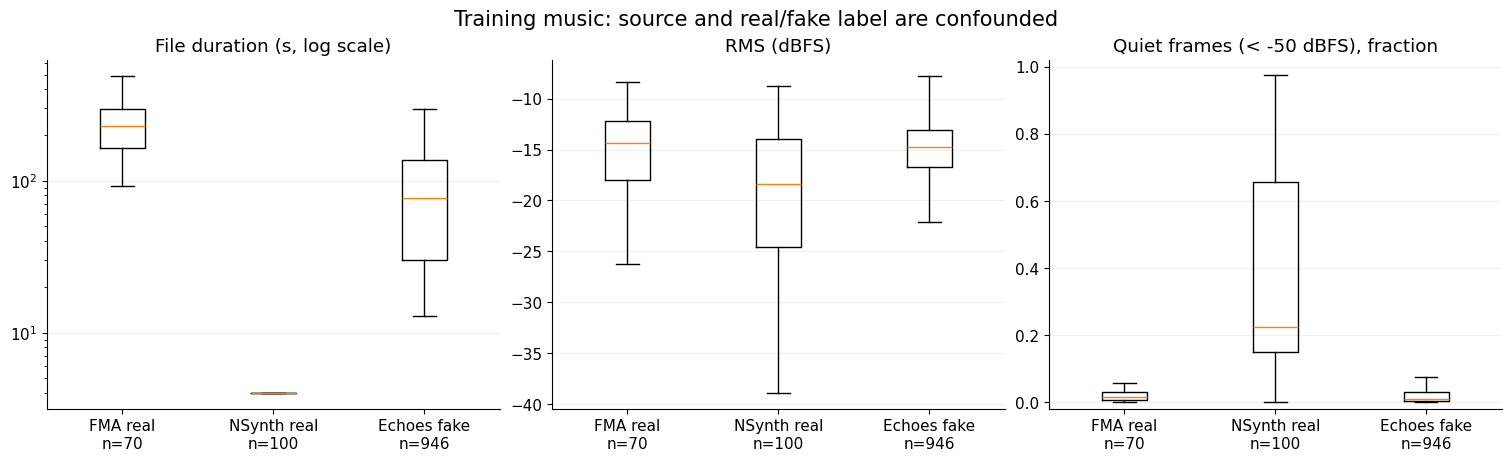

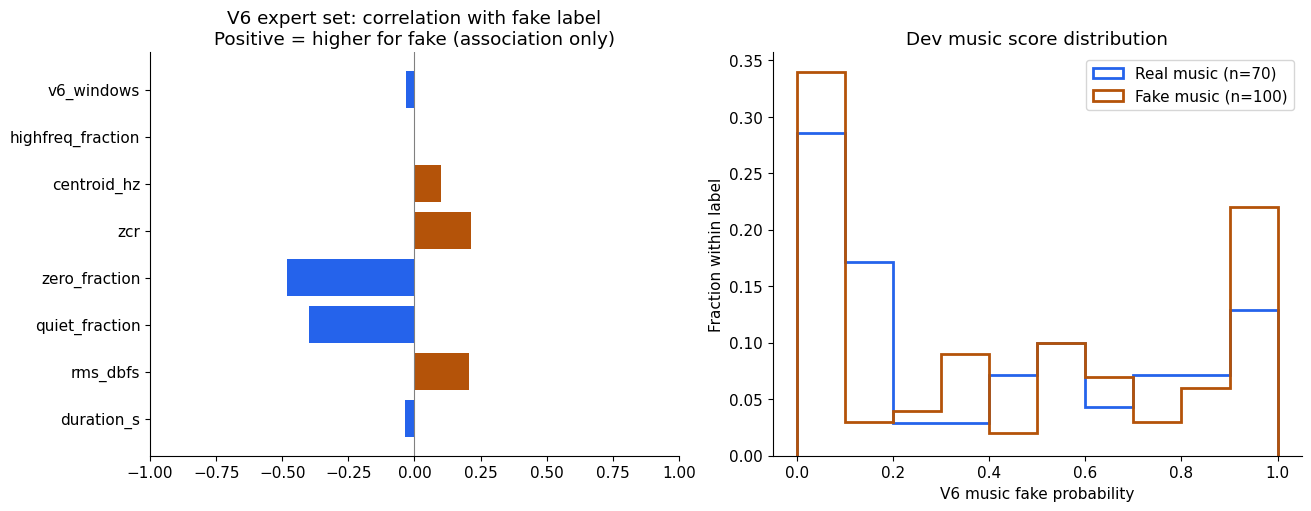

Results saved: /Users/choiwuseck/Documents/ChatGPT/데이콘/results/data_audit_20260915


In [6]:
plt.rcParams.update({'font.size':11,'figure.facecolor':'white','axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
cohorts=[('FMA real',[r for r in music if r['family']=='FMA']),('NSynth real',[r for r in music if r['family']=='nsynth']),('Echoes fake',[r for r in music if r['MUSIC_FAKE']=='1'])]
for ax,key,title in zip(axes,['duration_s','rms_dbfs','quiet_fraction'],['File duration (s, log scale)','RMS (dBFS)','Quiet frames (< -50 dBFS), fraction']):
    ax.boxplot([[r[key] for r in rr] for _,rr in cohorts],tick_labels=[f'{name}\nn={len(rr)}' for name,rr in cohorts],showfliers=False)
    if key=='duration_s': ax.set_yscale('log')
    if key=='quiet_fraction': ax.set_ylim(-.02,1.02)
    ax.set_title(title); ax.grid(axis='y',alpha=.2)
fig.suptitle('Training music: source and real/fake label are confounded',fontsize=15)
fig.savefig(OUT/'source_distributions.png',dpi=160);plt.show()
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
selected=[r for r in correlations if r['cohort']=='v6_expert_music']; values=[r['point_biserial_r'] or 0 for r in selected]
axes[0].barh([r['feature'] for r in selected],values,color=['#b45309' if v>0 else '#2563eb' for v in values]);axes[0].set_xlim(-1,1);axes[0].axvline(0,color='gray',lw=.8)
axes[0].set_title('V6 expert set: correlation with fake label\nPositive = higher for fake (association only)')
for y,color,label in [(0,'#2563eb','Real music'),(1,'#b45309','Fake music')]:
    a=[r['music_fake_probability'] for r in errors if r['music_fake']==y]
    axes[1].hist(a,bins=np.linspace(0,1,11),weights=np.ones(len(a))/len(a),histtype='step',linewidth=2,color=color,label=f'{label} (n={len(a)})')
axes[1].set(xlabel='V6 music fake probability',ylabel='Fraction within label',title='Dev music score distribution');axes[1].legend()
fig.savefig(OUT/'correlations_and_errors.png',dpi=160);plt.show()
(OUT/'summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False,allow_nan=False)+'\n')
print('Results saved:',OUT)


## Evaluation duplication sensitivity

The splice constructor repeats 10 source pairs across 20 iterations with deterministic cropping. This creates 20 duplicate pairs in each evaluation split. Keep the lexicographically first ID per PCM hash for the sensitivity calculation; do not compare this score to an undeduplicated baseline. Identical V6 predictions for identical PCM rule out score differences within each duplicate pair.

In [7]:
by_id={r['ID']:r for r in measured}
shared=[r for part in ['expert','fusion','dev'] for r in v6split[part] if r['ID'] in by_id]
summary['v6_input_pcm_check']={'checked':len(shared),'mismatches':sum(r['pcm_sha256']!=by_id[r['ID']]['pcm_sha256'] for r in shared)}
summary['duplicate_composition']=dict(Counter(by_id[g[0]]['split']+'/'+by_id[g[0]]['panel'] for g in summary['duplicate_pcm_groups']))
summary['quiet_review_composition']=dict(Counter(by_id[r['ID']]['split']+'/'+by_id[r['ID']]['family'] for r in review))
unique=[]; seen=set(); duplicates=[]
for r in dev:
    if r['pcm_sha256'] in seen:
        duplicates.append({'ID':r['ID'],'pcm_sha256':r['pcm_sha256'],'reason':'exact_duplicate_dev_audio'})
    else:
        unique.append(r);seen.add(r['pcm_sha256'])
summary['deduplicated_dev']={'files':len(unique),'metrics':official_metrics(unique,[pred_by_id[r['ID']] for r in unique])['metrics']}
summary['duplicate_prediction_max_delta']={k:max(abs(pred_by_id[g[0]][k]-pred_by_id[g[1]][k]) for g in summary['duplicate_pcm_groups'] if g[0] in pred_by_id) for k in ['FILE_FAKE_PROB','MUSIC_FAKE_PROB']}
save_csv('dev_duplicate_ids.csv',duplicates)
save_csv('dev_unique_ids.csv',[{'ID':r['ID'],'pcm_sha256':r['pcm_sha256']} for r in unique])
(OUT/'summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False,allow_nan=False)+'\n')
print('Deduplicated evaluation:',summary['deduplicated_dev'])
print('V6 input PCM reconciliation:',summary['v6_input_pcm_check'])


Deduplicated evaluation: {'files': 190, 'metrics': {'file_eer': 0.3358974358974359, 'voice_eer': 0.4291666666666667, 'music_eer': 0.4666666666666667, 'voice_presence_auc': None, 'music_presence_auc': 0.9948333333333336}}
V6 input PCM reconciliation: {'checked': 1726, 'mismatches': 0}


## Interpretation boundary

- Technical integrity does not prove a label is correct or that a clip contains music throughout.
- Source family is not a model input in V6; it is used here to expose dataset confounding.
- Full-file acoustic metadata differs from the separated-stem MERT input. A metadata shortcut is a risk signal, not proof that MERT used that shortcut.
- Quiet thresholds are review heuristics; natural note decay and pauses are not corrupt audio.
- Read the adjacent `REPORT.md` for findings and the next comparison design after inspecting the executed evidence.
